In [1]:
!pip install matplotlib numpy pandas seaborn tensorflow scikit-learn ucimlrepo shap


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 7.1 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of shap to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of ml-dtypes to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of numba to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.8/281.8 MB 24.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 72.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 62.8 MB/s eta 0:00:

# Import all required modules

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from numpy import loadtxt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, PowerTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from ucimlrepo import fetch_ucirepo
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
import shap


# Load data

In [3]:
df = pd.read_excel('Dry_Bean_Dataset.xlsx')

X = df.iloc[:, :16]
y = df['Class']

# Investigate the target class distribution

--- Class Distribution ---

   Class  Count Percentage
DERMASON   3546     26.05%
    SIRA   2636     19.37%
   SEKER   2027     14.89%
   HOROZ   1928     14.17%
    CALI   1630     11.98%
BARBUNYA   1322      9.71%
  BOMBAY    522      3.84%


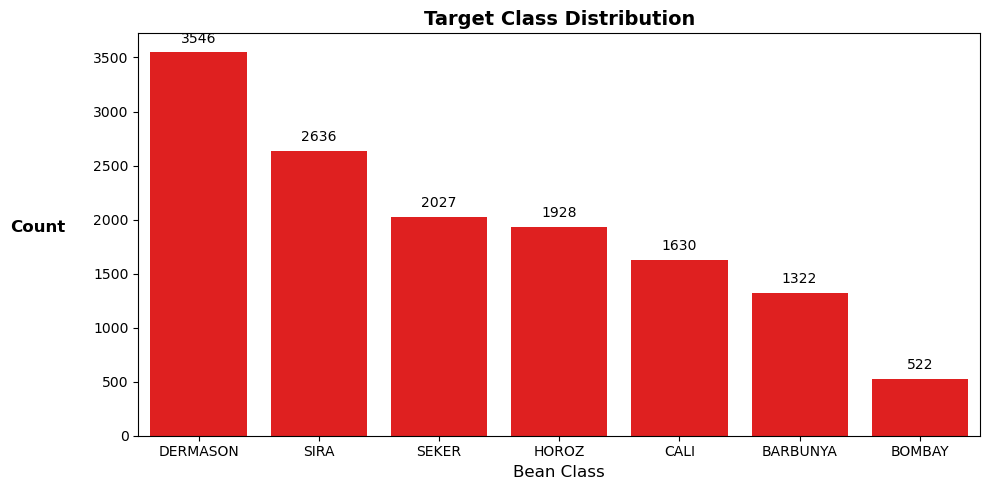

In [4]:
class_df = df['Class'].value_counts().reset_index()
class_df.columns = ['Class', 'Count']
class_df['Percentage'] = (class_df['Count'] / class_df['Count'].sum() * 100).map('{:.2f}%'.format)
print("--- Class Distribution ---\n")
print(class_df.to_string(index=False))
class_counts = df['Class'].value_counts()

plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=df, 
    x='Class', 
    order=class_counts.index, 
    color='red'
)


for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, xytext=(0, 5), textcoords='offset points')
plt.title('Target Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Bean Class', fontsize=12)
plt.ylabel('Count', fontsize=12, rotation=0, labelpad=40, fontweight='bold')
plt.tight_layout()
plt.show()

# Target Class Distribution Analysis 

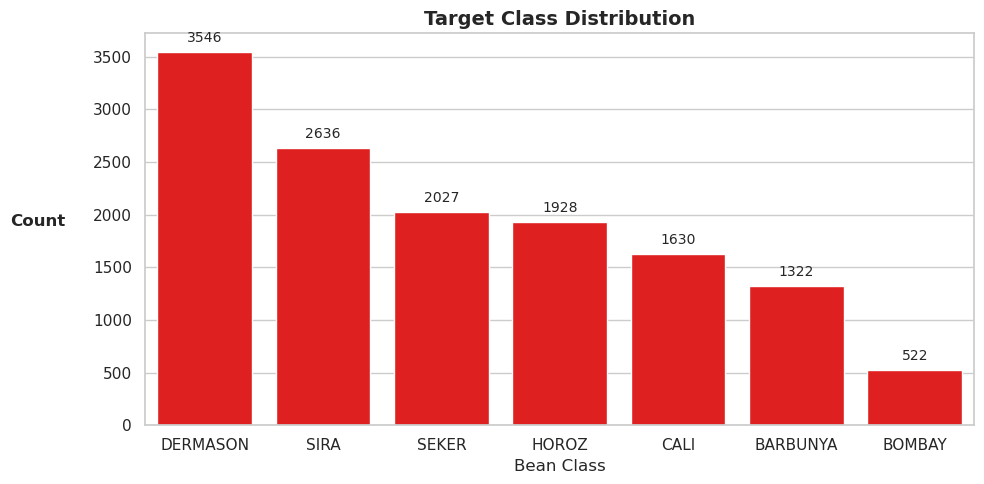

| Class | Count | Percentage |
| :--- | :--- | :--- |
| DERMASON | 3546 | 26.05% |
| SIRA | 2636 | 19.37% |
| SEKER | 2027 | 14.89% |
| HOROZ | 1928 | 14.17% |
| CALI | 1630 | 11.98% |
| BARBUNYA | 1322 | 9.71% |
| BOMBAY | 522 | 3.84% |



Above is the output of my Target Class Distribution Analysis. As we can see Dermason Beans make up the majority (26.05%) of the dataset while Bombay beans only make up a small amount (3.84%). 




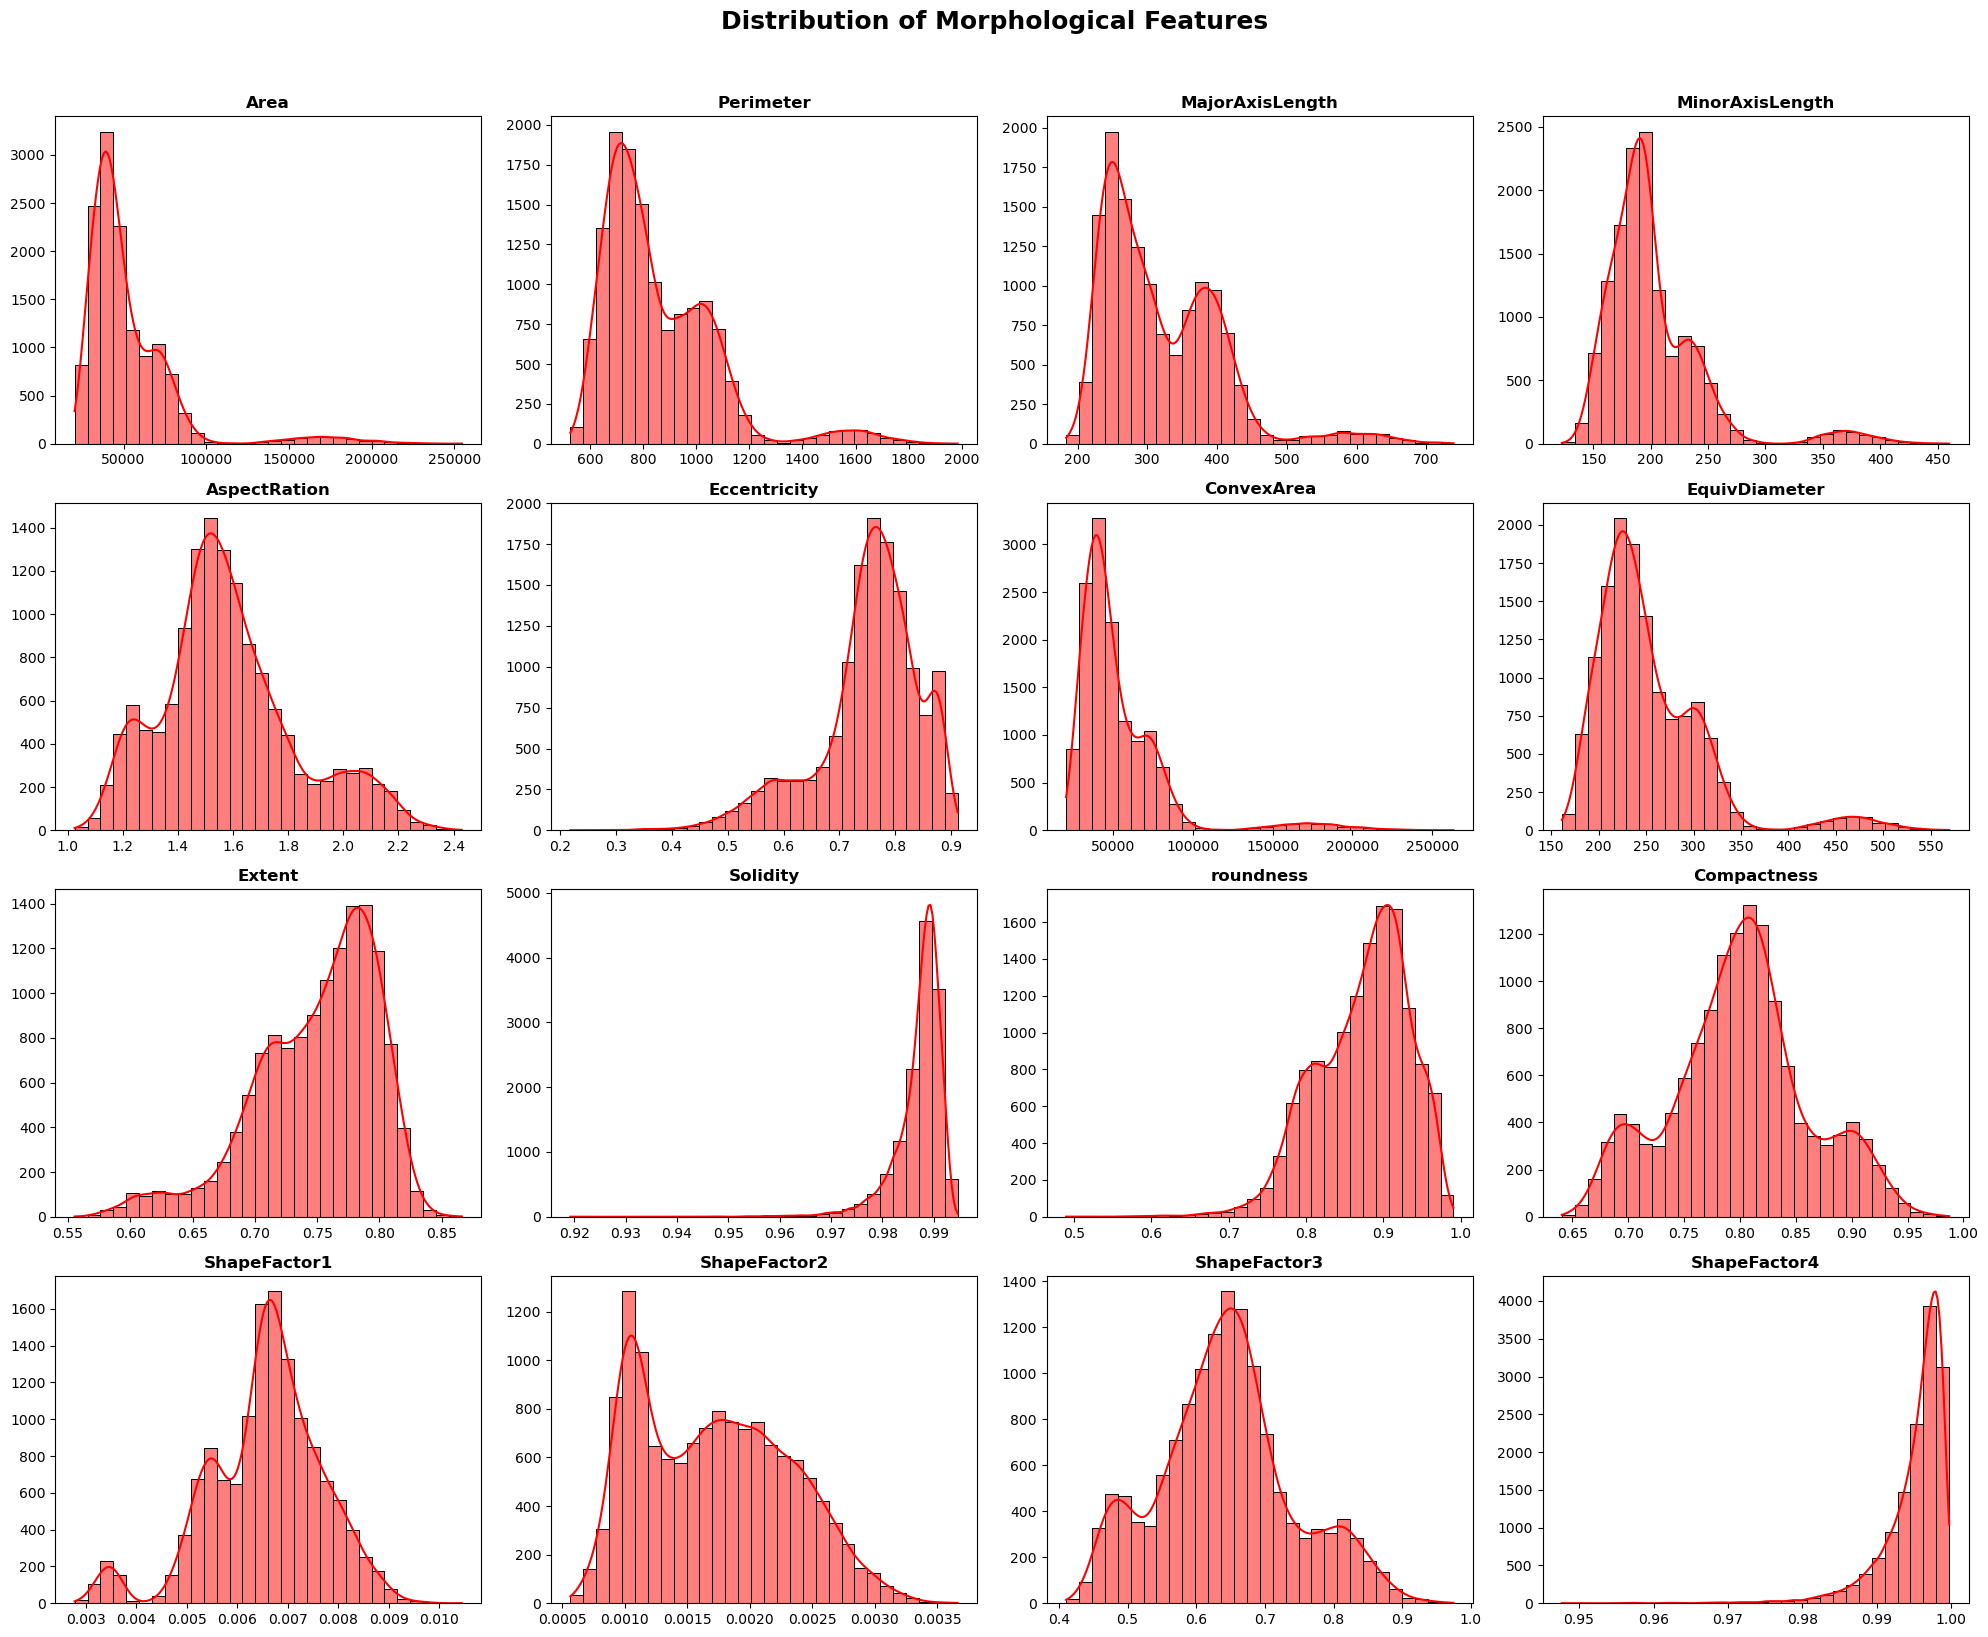

In [5]:
features = df.columns[:-1]

fig, axes = plt.subplots(4, 4, figsize=(20, 16)) 
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='red', bins=30)
    # Increase title and axis label font sizes
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='both', labelsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

plt.suptitle('Distribution of Morphological Features', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Feature Distribution Analysis 

Grouped boxplots to examine relation between size/shape features and bean type

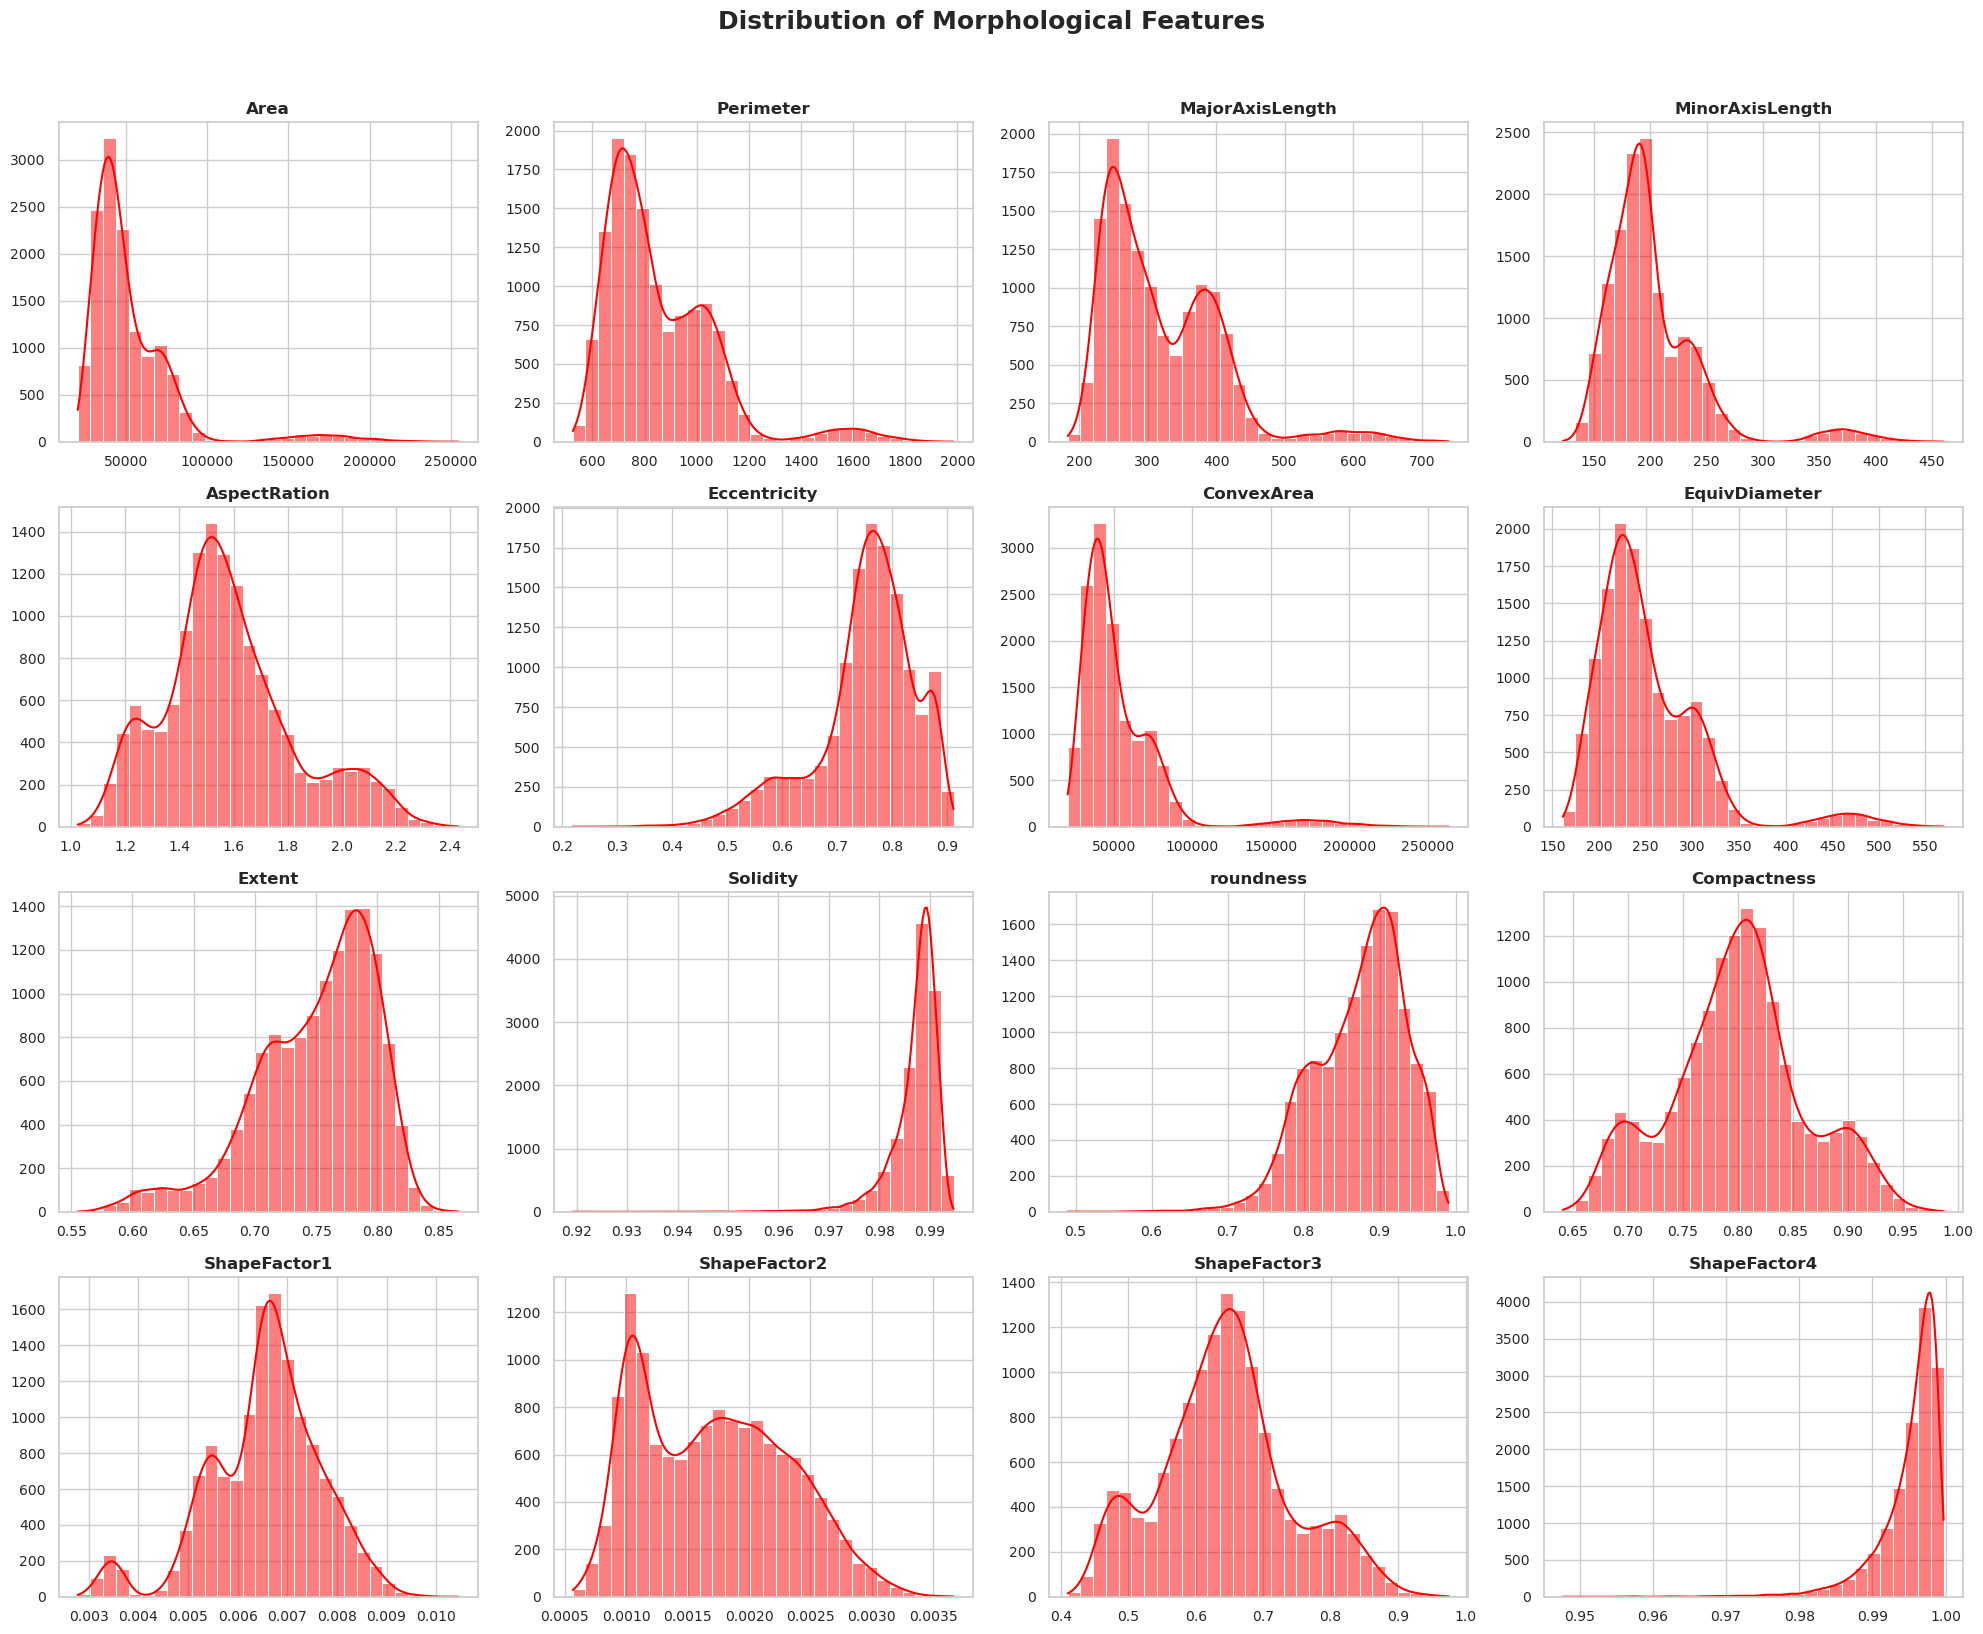
 




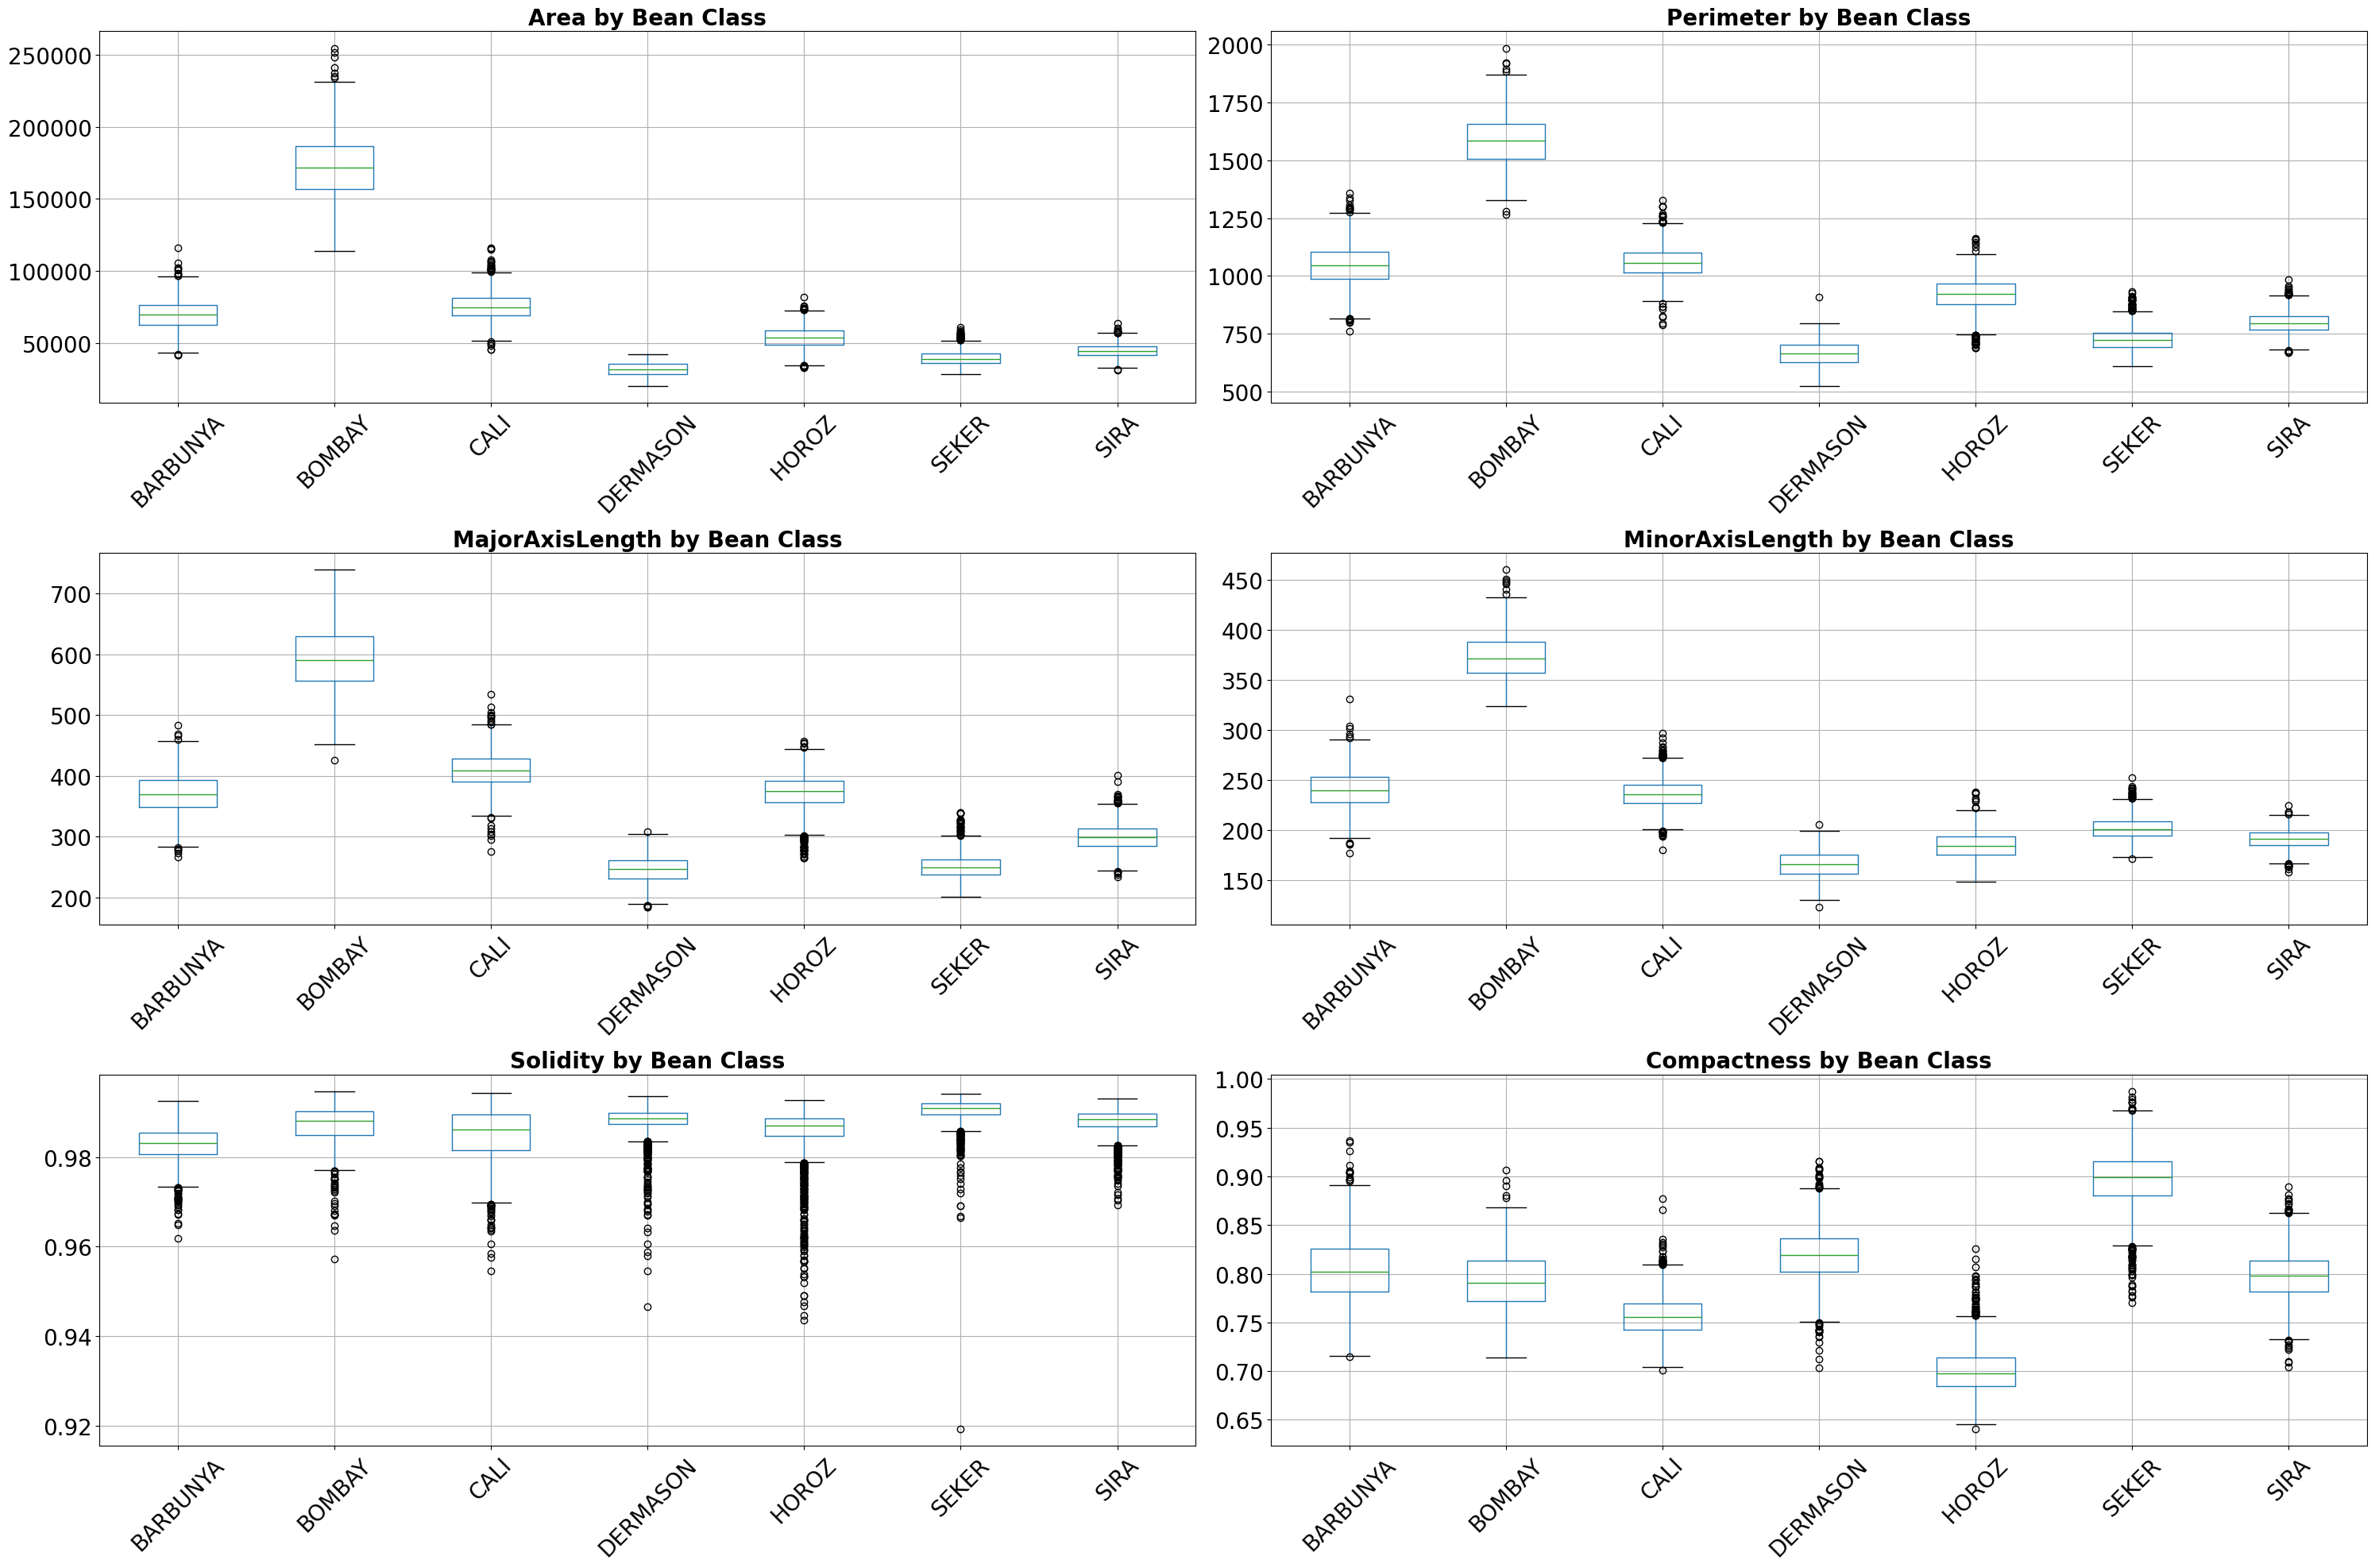

In [6]:
key_features = ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'Solidity', 'Compactness']

fig, axes = plt.subplots(3, 2, figsize=(30, 20))
axes = axes.flatten()

for i, col in enumerate(key_features):
    df.boxplot(column=col, by='Class', ax=axes[i], grid=True, fontsize=20)
    axes[i].set_title(f'{col} by Bean Class', fontsize=20, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    
plt.suptitle('')
plt.tight_layout()
plt.show()

# Grouped boxplots

Set of grouped box plots to help us understand the how the major features vary over different bean types. 

For example, the most obvious outlier is Bomabay beans which are by far the largest bean

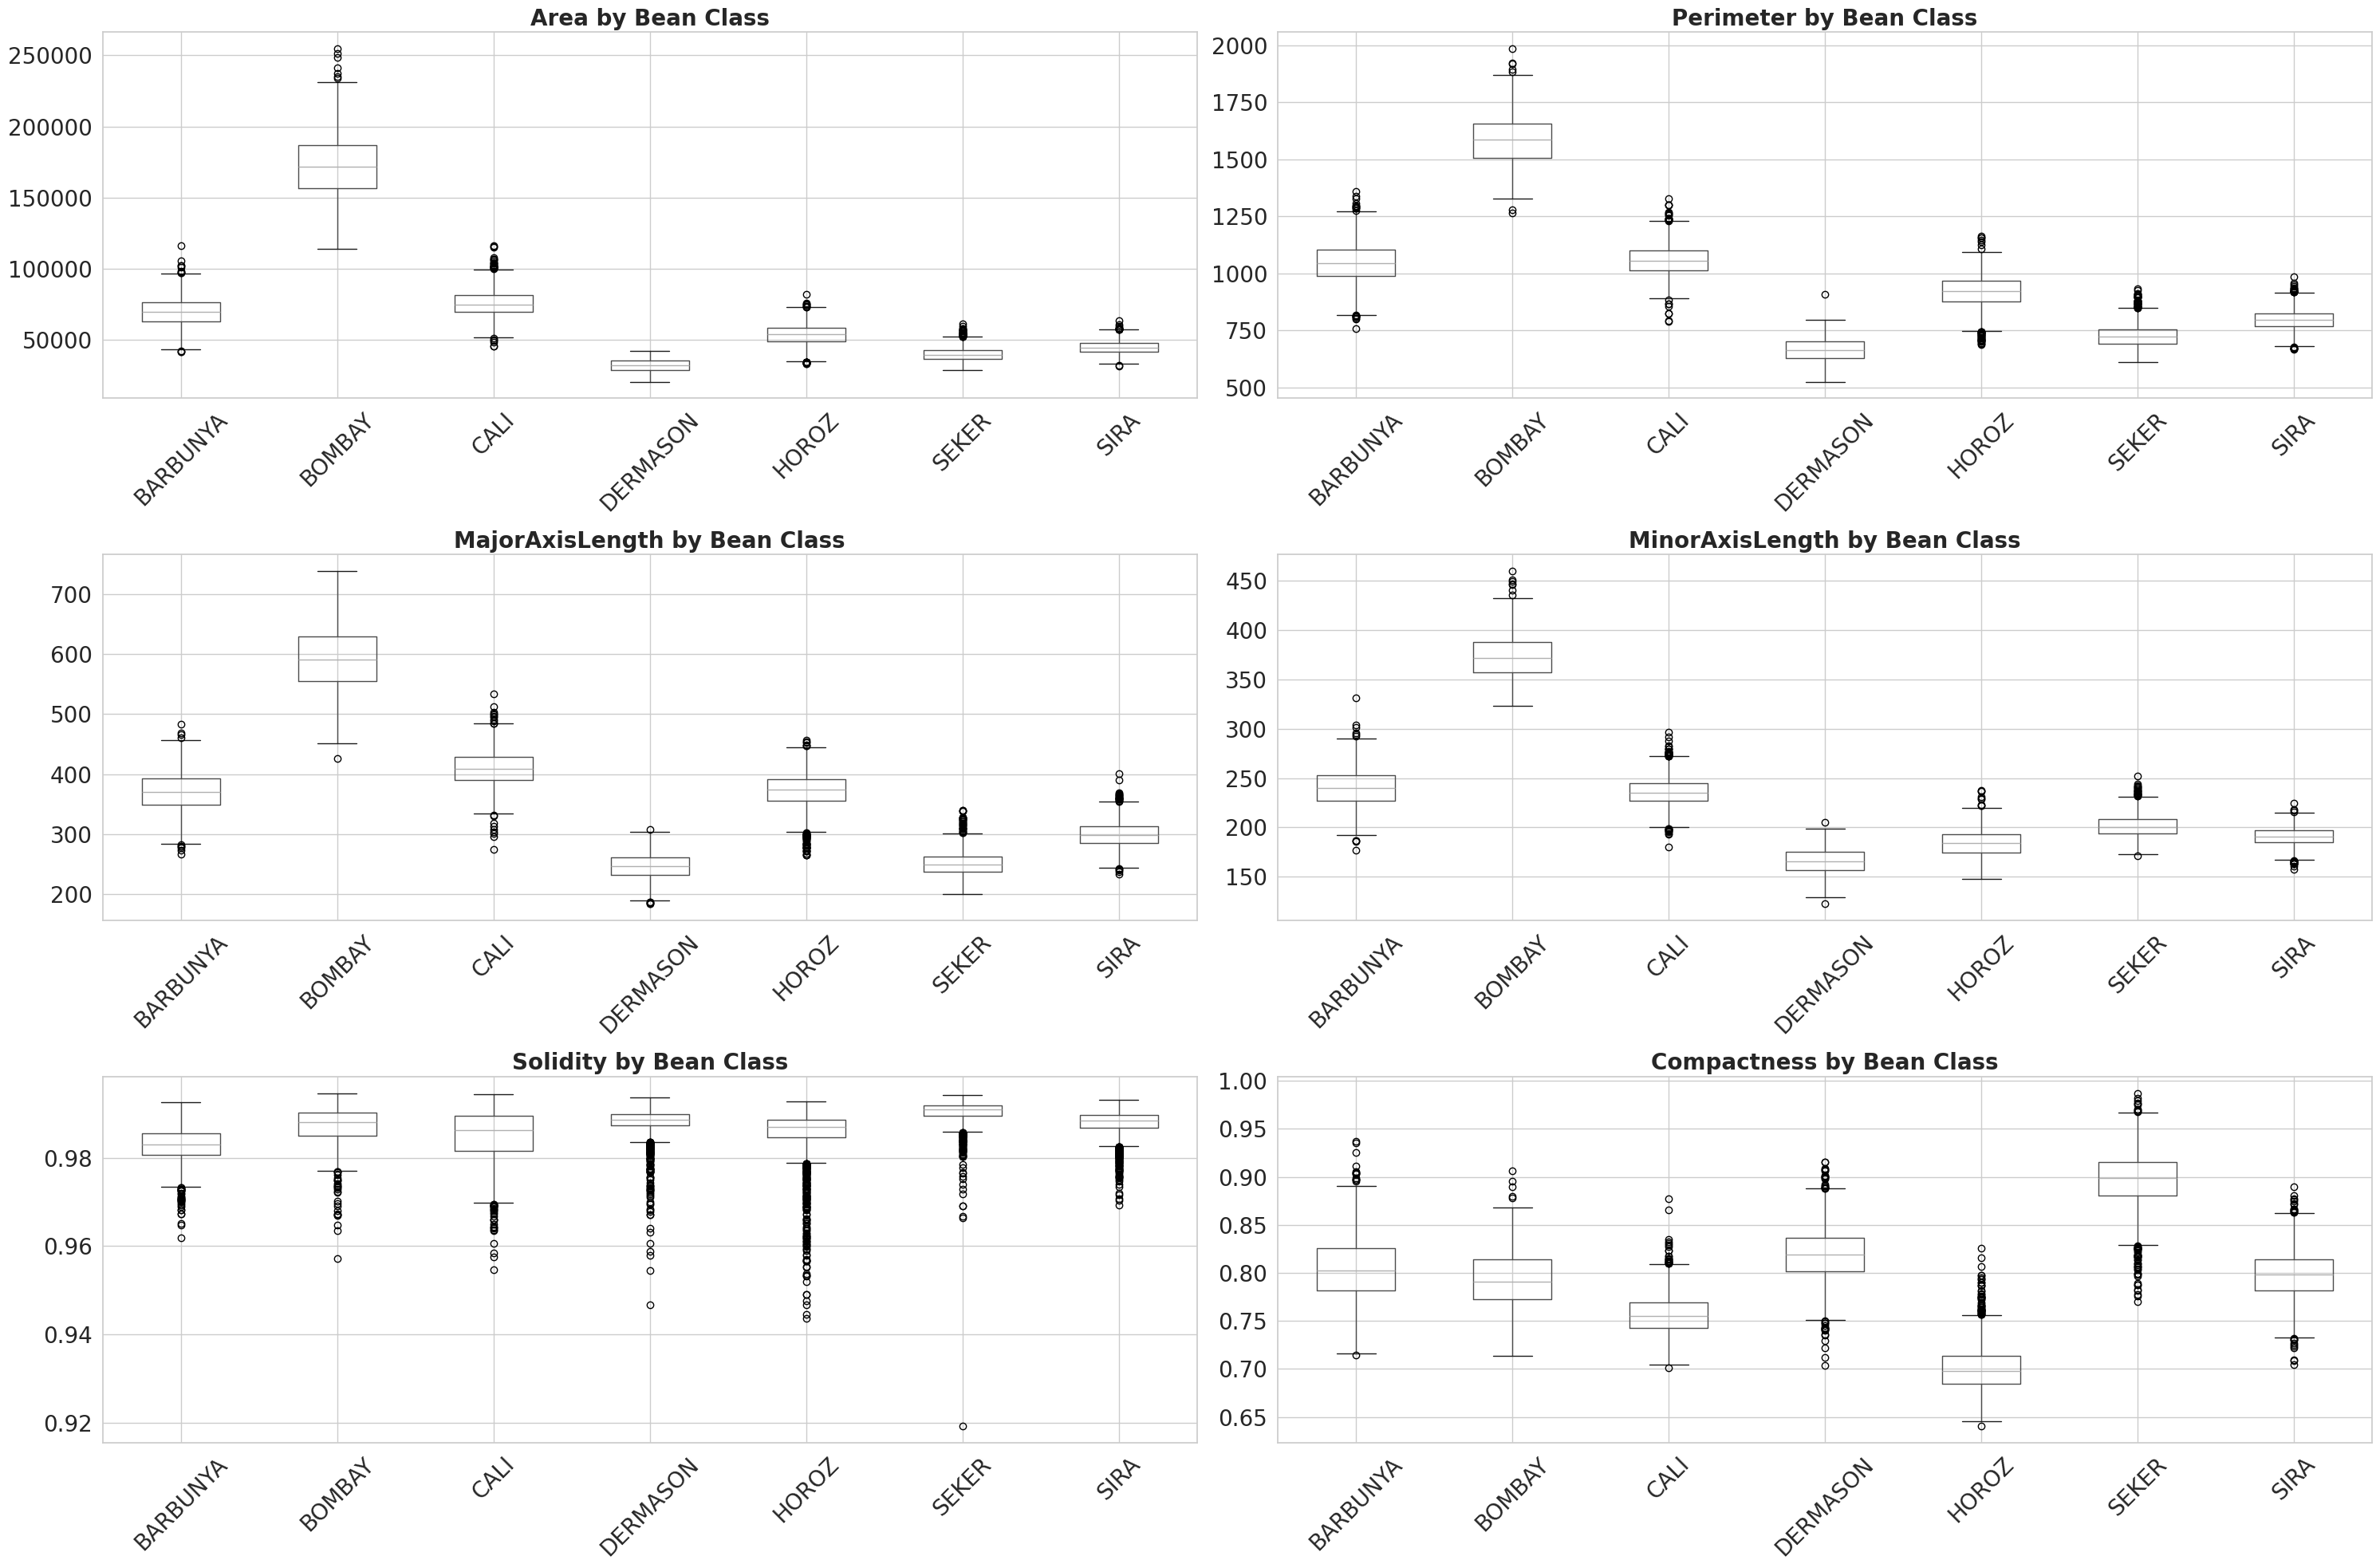




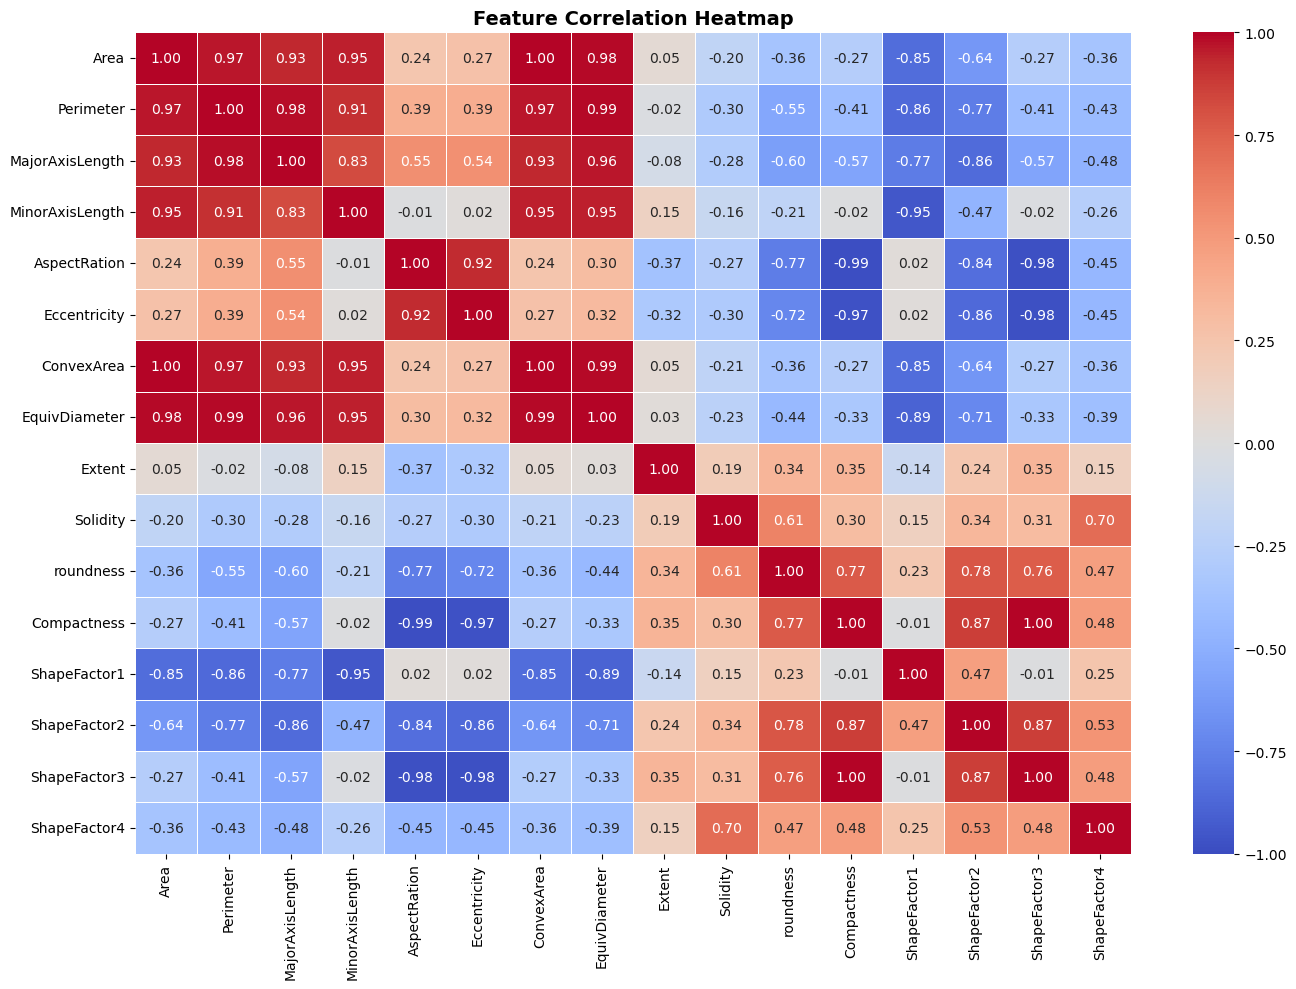

In [7]:
corr_matrix = df.drop(columns=['Class']).corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlation Matrix Heatmap

To determine the relationship between features and work out wether any are redundant.

The values show us the correlation between different features

| Value       | Correlation     |
| ----------- | --------------- |
| +1          | Strong positive |
| 0           | None            |
| -1          | Strong negative |

So we can see that these features carry the same information (r > 0.85):

#### High Positive Correlations ($r \ge +0.85$)
* `Area` - `ConvexArea` ($1.00$)
* `Compactness` - `ShapeFactor3` ($1.00$)
* `ConvexArea` - `EquivDiameter` ($0.99$)
* `Perimeter` - `EquivDiameter` ($0.99$)
* `Area` - `EquivDiameter` ($0.98$)
* `Perimeter` - `MajorAxisLength` ($0.98$)
* `Area` - `Perimeter` ($0.97$)
* `MajorAxisLength` - `EquivDiameter` ($0.96$)
* `MinorAxisLength` - `Area` ($0.95$)
* `MinorAxisLength` - `ConvexArea` ($0.95$)
* `MinorAxisLength` - `EquivDiameter` ($0.95$)
* `MajorAxisLength` - `ConvexArea` ($0.93$)
* `AspectRation` - `Eccentricity` ($0.92$)
* `ShapeFactor2` - `Compactness` ($0.87$)
* `ShapeFactor2` - `ShapeFactor3` ($0.87$)

---

#### Strong Negative Correlations ($r \le -0.85$)
* `AspectRation` - `Compactness` ($-0.99$)
* `AspectRation` - `ShapeFactor3` ($-0.98$)
* `Eccentricity` - `ShapeFactor3` ($-0.98$)
* `Eccentricity` - `Compactness` ($-0.97$)
* `MinorAxisLength` - `ShapeFactor1` ($-0.95$)
* `EquivDiameter` - `ShapeFactor1` ($-0.89$)
* `Perimeter` - `ShapeFactor1` ($-0.86$)
* `MajorAxisLength` - `ShapeFactor2` ($-0.86$)
* `Eccentricity` - `ShapeFactor2` ($-0.86$)
* `Area` - `ShapeFactor1` ($-0.85$)
* `ConvexArea` - `ShapeFactor1` ($-0.85$)

#### What does this show us?

Severe Multicollinearity - Many features have a very high correlation values (near -1 or +1) meaning that they show the same thing. 

To make this a clean dataset without redundant features, I am going to drop these features:

* `ConvexArea` - Duplicate of `Area`
* `EquivDiamater` - Just shows `Area`/`Diamater`
* `ShapeFactor3` - Duplicate of `Compactness`
* `Eccentricity` - Duplicate of `AspectRation`
* `Perimiter` - Very similar to `Area` and `MajorAxisLength`
* `ShapeFactor1` - Almost pefect negative correlation with `MinorAxisLength`
* `ShapeFactor2` - Very similar to `ShapeFactor3` and `Compactness`

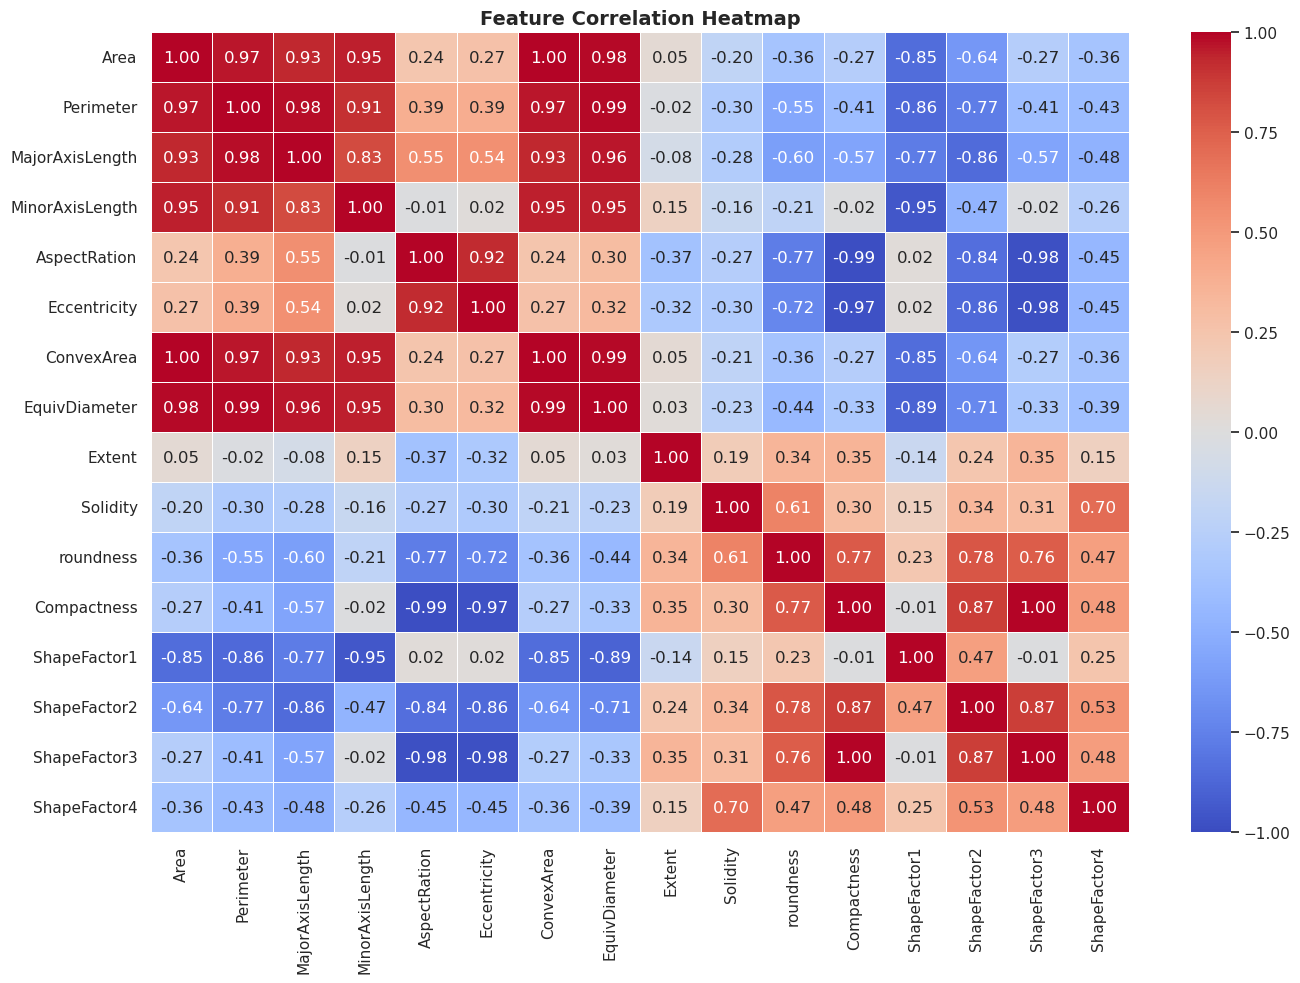

# Date processing and splitting

In [8]:
# Drop the redundat data that we decided on during the Correlation Matrix
X = df.drop(columns=['Class', 'ShapeFactor3', 'ConvexArea', 
                     'EquivDiameter', 'Eccentricity', 'Perimeter', 
                     'ShapeFactor1', 'ShapeFactor2' ])

# Isolate the class, this is what we want the model to predict
y = df['Class']

# Encode labels - so strings become int
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the data into trainign and testing. 80:20 split for training:testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Standardise the test and training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train classical ML models

In [9]:
# Setup our models
models = {
    # LogisticRegression with 1000 iterations, allows time for the data to converge
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    # Decision Tree Classifier with a max depth of 10 to prevent over-fitting
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    # Random Forest with 100 trees, more has show to not have much of an effect on accuracy
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=42)
}

# Init results list
results = []

# Start the lopp through the models
for name, model in models.items():
    # Logist Regression requires the scaled data. The rest do not, I tried giving all models scaled data but found a considerable drop in performance. 
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        # Train the model on the training data
        model.fit(X_train, y_train)
        # Create predictions from the model using the test data (remaining 20%)
        y_pred = model.predict(X_test)

    # Generate Precision, Recall and F1-score data
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

    # Save to the results 
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred), # The % of correct predictions 
        'Precision (Macro)': prec, # True Positives / True Positves + False Positives 
        'Recall (Macro)': rec, # True Positves / True Positives + False Negatives 
        'F1-Score (Macro)': f1, # 2 * ((Precision * Recall) / (Precision + Recall)) - Harmonic Mean
    })

# Format the results into a table, sort by Accuracy
results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("========================== Classical ML Model Comparison ==========================\n")
print(results_df.to_string(index=False))

========================== Classical ML Model Comparison ==========================

              Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
      Random Forest  0.923981           0.937437        0.933980          0.935536
  Gradient Boosting  0.921410           0.936423        0.931344          0.933722
Logistic Regression  0.919207           0.933344        0.929917          0.931407
      Decision Tree  0.901212           0.919444        0.915971          0.917627


| Model               | Accuracy | Precision (Macro) | Recall (Macro) | F1-Score (Macro) |
| ------------------- | -------- | ----------------- | -------------- | ---------------- |
| Random Forest       | 0.923981 | 0.937668          | 0.933714       | 0.935566         |
| Gradient Boosting   | 0.920308 | 0.936058          | 0.930055       | 0.932885         |
| Logistic Regression | 0.919574 | 0.933535          | 0.930188       | 0.931629         |
| Decision Tree       | 0.901212 | 0.919444          | 0.915971       | 0.917627         |


In [10]:
# Set random seeds so that the results are reproducable
tf.random.set_seed(42)
np.random.seed(42)

# Retrive class names form earlier
class_names = label_encoder.classes_
# Defined the number of classes 
num_classes = len(class_names)

# Define a Sequential model object
model = Sequential()
model.add(Input(shape=(X_train_scaled.shape[1],))) # This is where the data arrives
model.add(Dense(128, activation='relu')) # Introduces non-linearity 
model.add(Dropout(0.3)) # Randomly sets 30% of neuron activations to 0, this forces the model to learn independant features
model.add(Dense(64, activation='relu')) # Takes 128 features and abstracts them to 64
model.add(Dropout(0.2)) # Randomly sets 20% of neuron activations to 0
model.add(Dense(32, activation='relu')) # Takes 64 features and abstracts them to 32
model.add(Dense(num_classes, activation='softmax')) # Takes 32 features and asbtracts them down to our bean classes. Softmax converts them into probability scores between 0 and 1

# Complie the model 
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Prevent the model from over-fitting by stopping the training once returns start to diminish 
early_stop = EarlyStopping(
    monitor='val_loss',  # Use validation loss as the metric for determing training returns 
    patience=12,  # Allow 12 epcochs with no increase in return before training stops
    restore_best_weights=True # Drop the weights from the 12 non-imporving epochs
)

# Execute the training loops 
history = model.fit(
    X_train_scaled, y_train, # Give the model the scaled training data 
    validation_split=0.15, # Use 15% of the training data for validation 
    epochs=1000, # Allow 1000 cycles of the training data, enough for the early stop to kick in
    batch_size=64, # Evaluate 64 samples at a time before calculating gradients/weights 
    callbacks=[early_stop],
    verbose=0
)

# 5. Predict & Evaluate
preds_prob = model.predict(X_test_scaled)
preds = np.argmax(preds_prob, axis=1)

acc = accuracy_score(y_test, preds)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='macro')

# Append the results 
ann_results = pd.DataFrame([{
    'Model': 'ANN (Keras)',
    'Accuracy': acc,
    'Precision (Macro)': prec,
    'Recall (Macro)': rec,
    'F1-Score (Macro)': f1
}])

# Merge the results with the classical models
all_models_df = pd.concat([results_df, ann_results], ignore_index=True).sort_values(by='Accuracy', ascending=False)

# Print the results in a table
print("=== Complete Model Comparison (Classical vs ANN) ===")
all_models_df

86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step
=== Complete Model Comparison (Classical vs ANN) ===


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
4,ANN (Keras),0.925450,0.939472,0.935974,0.937564
0,Random Forest,0.923981,0.937437,0.933980,0.935536
1,Gradient Boosting,0.921410,0.936423,0.931344,0.933722
2,Logistic Regression,0.919207,0.933344,0.929917,0.931407
3,Decision Tree,0.901212,0.919444,0.915971,0.917627


# Results

| Model | Accuracy | Precision (Macro) | Recall (Macro) | F1-Score (Macro) |
| --- | --- | --- | --- | --- |
| ANN (Keras) | 0.924348 | 0.937617 | 0.934100 | 0.935636 |
| Random Forest | 0.923981 | 0.937437 | 0.933980 | 0.935536 |
| Gradient Boosting | 0.921410 | 0.936423 | 0.931344 | 0.933722 |
| Logistic Regression | 0.919207 | 0.933344 | 0.929917 | 0.931407 |
| Decision Tree | 0.901212 | 0.919444 | 0.915971 | 0.917627 |

As we can see the ANN model has beaten the classical model in every metric


=== Top Classical Model vs ANN ===
Top Classical: Random Forest (Accuracy: 0.9240)
ANN (Keras)  : Accuracy: 0.9254
Difference   : 0.0015


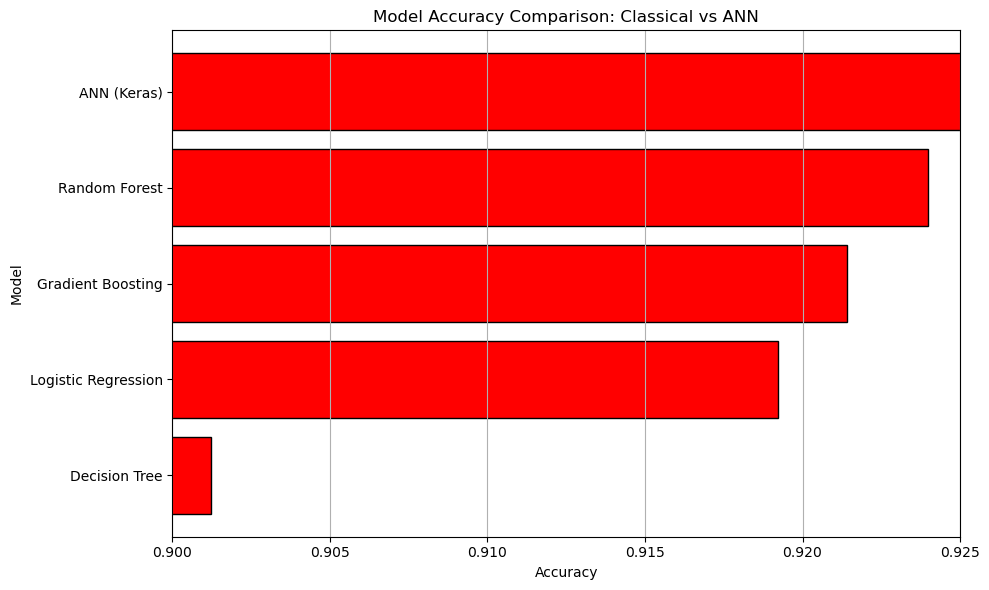

In [11]:
# List of all classical Models
best_classical = all_models_df[all_models_df['Model'] != 'ANN (Keras)'].iloc[0]

# Just the ANN model
ann_metrics = all_models_df[all_models_df['Model'] == 'ANN (Keras)'].iloc[0]

# Print the metrics of the most accurate classical model alongside the ANN model
print("=== Top Classical Model vs ANN ===")
print(f"Top Classical: {best_classical['Model']} (Accuracy: {best_classical['Accuracy']:.4f})")
print(f"ANN (Keras)  : Accuracy: {ann_metrics['Accuracy']:.4f}")
print(f"Difference   : {abs(best_classical['Accuracy'] - ann_metrics['Accuracy']):.4f}")

# Create a horizontal bar chart 
plt.figure(figsize=(10, 6))

# Sort by accuracy 
df_sorted = all_models_df.sort_values(by='Accuracy', ascending=True)

plt.barh(df_sorted['Model'], df_sorted['Accuracy'], color='red', edgecolor='black')
plt.title('Model Accuracy Comparison: Classical vs ANN')
plt.xlabel('Accuracy')
plt.ylabel('Model')

# Limit between 0.90 and 0.925 for best visual clarity on model differences 
plt.xlim(0.90, 0.925)
plt.grid(axis='x', linestyle='-', alpha=1)
plt.tight_layout()
plt.show()

Adjusted Rand Index (K-Means vs True Classes): 0.4894


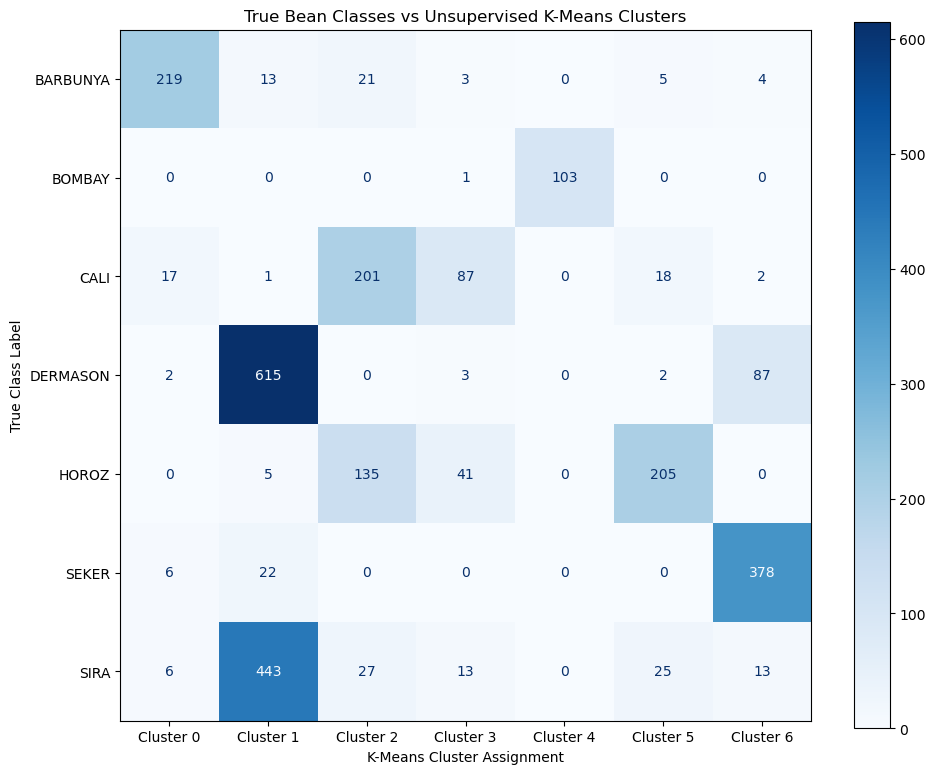

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Apply K-Means
kmeans = KMeans(n_clusters=num_classes, random_state=42, n_init=100)
cluster_labels = kmeans.fit_predict(X_test_scaled)

# 2. Adjusted Rand Index (1.0 = perfect match, 0.0 = random assignment)
ari_score = adjusted_rand_score(y_test, cluster_labels)
print(f"Adjusted Rand Index (K-Means vs True Classes): {ari_score:.4f}")

# 3. Plot Confusion Matrix
cm_clustering = confusion_matrix(y_test, cluster_labels)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_clustering, 
    display_labels=[f'Cluster {i}' for i in range(num_classes)]
)

disp.plot(cmap='Blues', ax=ax, values_format='d', colorbar=True)
ax.set_yticklabels(class_names)
ax.set_title('True Bean Classes vs Unsupervised K-Means Clusters')
ax.set_xlabel('K-Means Cluster Assignment')
ax.set_ylabel('True Class Label')
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 325us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 265us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 262us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 269us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 266us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 268us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 274us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 269us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 267us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 267us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16

/tmp/ipykernel_145/1926124798.py:29: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(class_0_shap, test_subset, feature_names=feature_names_list)


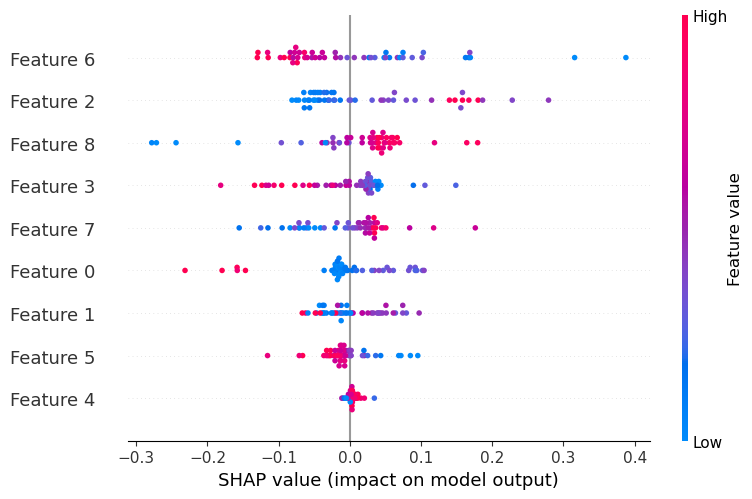

In [12]:
# 1. Summarize background data to speed up execution
background_summary = shap.kmeans(X_train_scaled, 10)

# 2. Initialize explainer
explainer = shap.KernelExplainer(model.predict, background_summary)

# 3. Calculate SHAP values for a subset of samples
test_subset = X_test_scaled[:50]
shap_values = explainer.shap_values(test_subset)

# 4. Extract feature names (uses DataFrame columns if available, otherwise generic names)
if hasattr(X_train_scaled, "columns"):
    feature_names_list = list(X_train_scaled.columns)
else:
    feature_names_list = [f"Feature {i}" for i in range(X_train_scaled.shape[1])]

# 5. Extract SHAP values for Class 0, safely handling 3D arrays vs lists
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Shape: (samples, features, classes) -> slice Class 0 along the 3rd dimension
    class_0_shap = shap_values[:, :, 0]
elif isinstance(shap_values, list):
    # List of 2D arrays per class -> select first class
    class_0_shap = shap_values[0]
else:
    class_0_shap = shap_values

# 6. Plot summary for Class 0
print(f"Showing feature importance for class: {class_names[0]}")
shap.summary_plot(class_0_shap, test_subset, feature_names=feature_names_list)

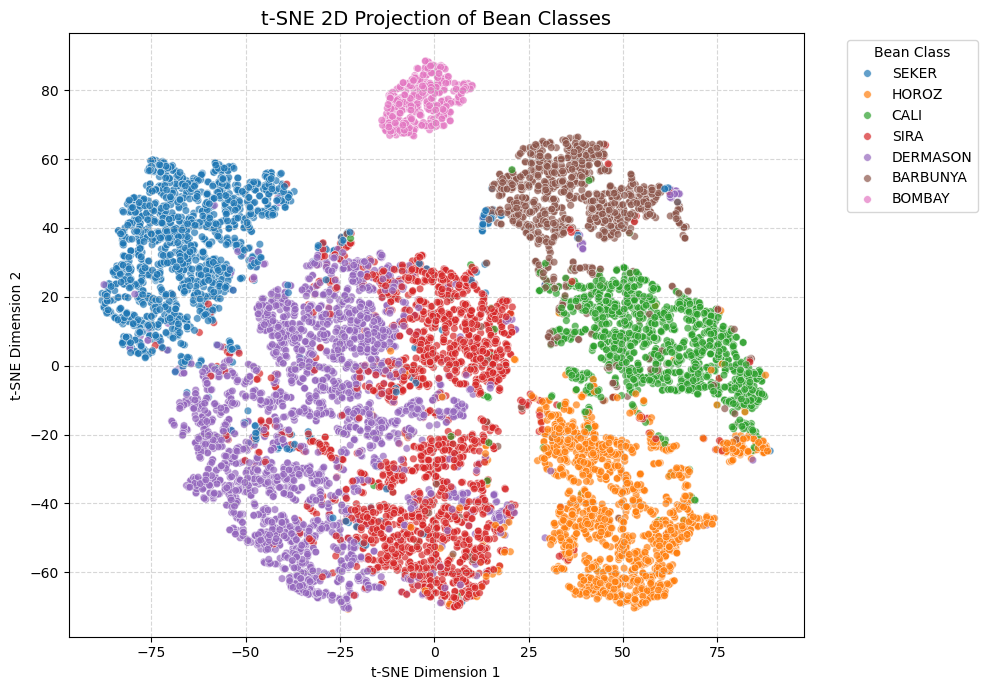

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# 1. Fit t-SNE using 'n_iter' instead of 'max_iter'
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
X_tsne = tsne.fit_transform(X_train_scaled)

# 2. Plot results
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_tsne[:, 0], 
    y=X_tsne[:, 1], 
    hue=class_names[y_train], 
    palette='tab10', 
    alpha=0.7,
    s=30
)

plt.title('t-SNE 2D Projection of Bean Classes', fontsize=14)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Bean Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

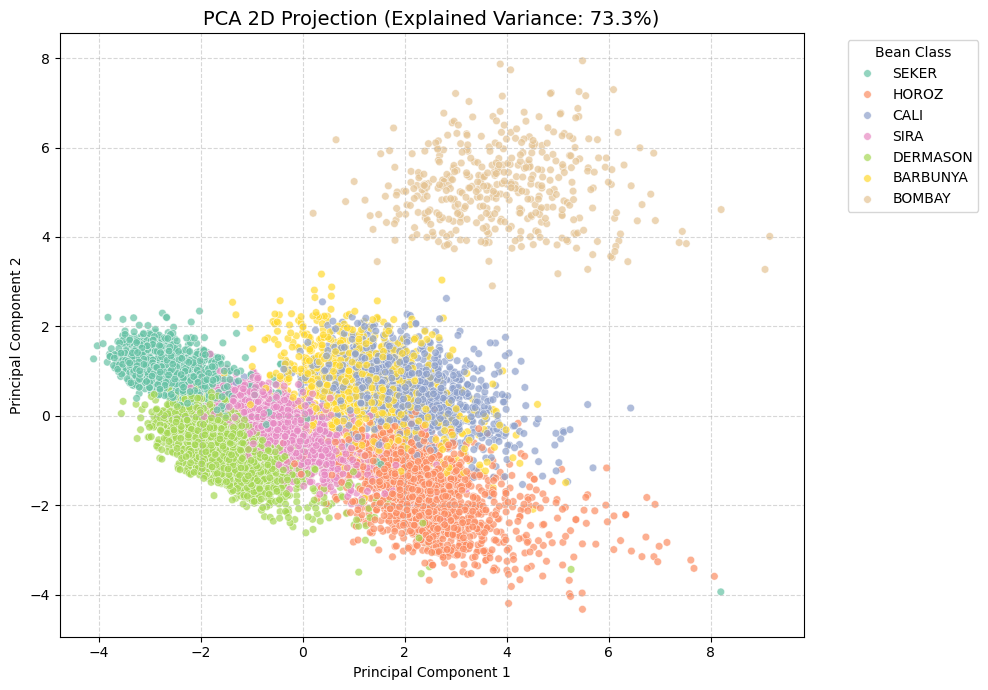

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Fit PCA on scaled feature data
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

# 2. Plot results
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=class_names[y_train], 
    palette='Set2', 
    alpha=0.7,
    s=30
)

plt.title(f'PCA 2D Projection (Explained Variance: {sum(pca.explained_variance_ratio_)*100:.1f}%)', fontsize=14)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Bean Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()